# DEV · Problema 2 · Compra Fácil Bajío: reseñas negativas
**Responsable:** Paula · Especificaciones del cliente **en la prueba, con umbral 0.5**: exhaustividad ≥ 90 % y precisión ≥ 85 %. El modelo lo entrenamos nosotras; no usamos ningún LLM por API.

**Reglas que seguimos en todo el cuaderno**
1. La carga y la prueba se hacen con el código **exacto** del PDF.
2. **Sin fuga:** el TF‑IDF y el vocabulario se ajustan **solo con `train`**. Validación y prueba solo se transforman.
3. **Toda decisión se toma con validación** (partición `validation` del dataset): qué hacer con las 3 estrellas, el número de épocas (EarlyStopping) y qué modelo elegir.
4. La **prueba se usa una sola vez**, al final (sección 6), con umbral fijo de 0.5.

## 0. Entorno
Usamos **Keras 3 con el backend de PyTorch**, para entrenar en la GPU (RTX 4060) de este equipo. TensorFlow no tiene GPU en Windows nativo. El modelo se guarda igual en formato `.keras`.
`KERAS_BACKEND` se define **antes** de importar Keras. Fijamos semillas para que los resultados sean reproducibles.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import time, json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import keras, torch
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import recall_score, precision_score, accuracy_score, confusion_matrix

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
pd.set_option("display.max_colwidth", 200)
print("Keras", keras.__version__, "| backend:", keras.backend.backend(), "| GPU:", torch.cuda.is_available())

# Colores fijos de las gráficas: negativa = naranja, positiva = azul, 3 estrellas = gris
C_NEG, C_POS, C_NEU = "#eb6834", "#2a78d6", "#8a8984"

Keras 3.15.1 | backend: torch | GPU: True


## 1. Datos y exploración
Carga **exacta** del PDF (no se modifica):

In [2]:
import pandas as pd

URL = "https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/main/{}.jsonl"
partes = {p: pd.read_json(URL.format(p), lines=True) for p in ["train", "validation", "test"]}
for df in partes.values():
    df["estrellas"] = df["label"] + 1                 # label va de 0 a 4
train, val, test = partes["train"], partes["validation"], partes["test"]

# Prueba del cliente: la partición test sin las de 3 estrellas (4,000 reseñas, mitad negativas).
# 1 = negativa. No la toquen hasta el final.
prueba = test[test["estrellas"] != 3]
X_prueba, y_prueba = prueba["text"].values, (prueba["estrellas"] <= 2).astype(int).values

### 1.1 Tamaño y distribución de estrellas por partición

In [3]:
print({p: df.shape for p, df in partes.items()})
print("Prueba del cliente:", len(X_prueba), "reseñas | negativas:", y_prueba.sum())

conteo = pd.DataFrame({p: df["estrellas"].value_counts().sort_index() for p, df in partes.items()})
conteo.index.name = "estrellas"
conteo

{'train': (200000, 5), 'validation': (5000, 5), 'test': (5000, 5)}
Prueba del cliente: 4000 reseñas | negativas: 2000


,train,validation,test
estrellas,,,
1,40000,1000,1000
2,40000,1000,1000
3,40000,1000,1000
4,40000,1000,1000
5,40000,1000,1000


### 1.2 Balance de clases (negativa = 1–2 ★, positiva = 4–5 ★, 3 ★ = neutral)

In [4]:
def grupo(e):
    return np.where(e <= 2, "negativa (1-2)", np.where(e == 3, "neutral (3)", "positiva (4-5)"))

balance = pd.DataFrame({p: pd.Series(grupo(df["estrellas"])).value_counts(normalize=True).round(3)
                        for p, df in partes.items()})
balance

,train,validation,test
negativa (1-2),0.4,0.4,0.4
positiva (4-5),0.4,0.4,0.4
neutral (3),0.2,0.2,0.2


**Lectura:** las tres particiones tienen exactamente **20 % de cada estrella**. Por eso, sin las 3 estrellas, las clases quedan **50/50** (80,000 negativas contra 80,000 positivas en train). El balance perfecto tiene dos consecuencias:
- no hace falta ponderar clases;
- la «clase mayoritaria» no existe como línea base, así que usamos una regla trivial (sección 3).

### 1.3 Longitud de las reseñas (palabras)

In [5]:
for df in partes.values():
    df["palabras"] = df["text"].str.split().str.len()

print("Mediana de palabras por partición:", {p: int(df["palabras"].median()) for p, df in partes.items()})
train.groupby(grupo(train["estrellas"]))["palabras"].describe(percentiles=[.5, .9, .95]).round(1)

Mediana de palabras por partición: {'train': 22, 'validation': 22, 'test': 22}


,count,mean,std,min,50%,90%,95%,max
negativa (1-2),80000.0,29.9,24.4,2.0,23.0,57.0,75.0,506.0
neutral (3),40000.0,28.8,24.6,2.0,23.0,56.0,74.0,458.0
positiva (4-5),80000.0,25.2,23.5,2.0,20.0,50.0,67.0,551.0


### 1.4 Ejemplos (uno por número de estrellas, de train)

In [6]:
ejemplos = train.groupby("estrellas").sample(1, random_state=SEMILLA)[["estrellas", "text"]]
ejemplos

,estrellas,text
32823,1,Pedí la botella por comodidad al salir a pasear con Sherlock... Pero ha sido una decepción. Cuando llegó tenia el plástico que ancla la botella con el bebedero roto. Me he puesto en contacto con e...
64069,2,el diseño es bastante feo. Nada que ver con la foto. La calidad normal.
105830,3,"Son un poco débiles, pero sirven para guardar cosas importantes, los cajones tienen su maña, pero por el precio y su cometido esta bien."
130322,4,Lanza los mosquitos por el aire de su potencia. No deja que se acerque ni uno lejos de el.
163701,5,No estaba en casa y me lo han dejado donde les dije asique perfecto. No estaba dañado ni nada


### 1.5 Gráfica 1 — Distribución de estrellas y qué se vuelve cada una

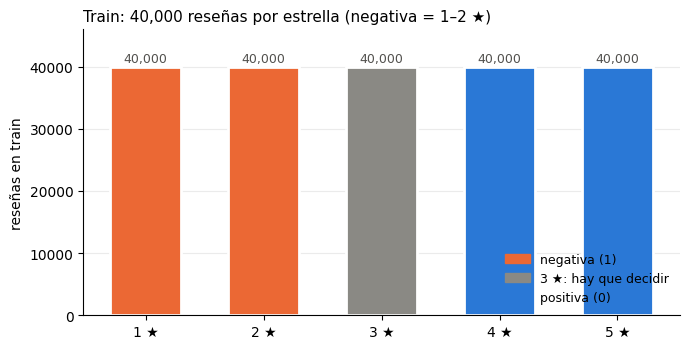

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
cnt = train["estrellas"].value_counts().sort_index()
colores = [C_NEG, C_NEG, C_NEU, C_POS, C_POS]
ax.bar(cnt.index, cnt.values, color=colores, width=0.6, edgecolor="white", linewidth=2)
for x, v in zip(cnt.index, cnt.values):
    ax.text(x, v + 800, f"{v:,}", ha="center", fontsize=9, color="#52514e")
ax.set_xticks([1, 2, 3, 4, 5], ["1 ★", "2 ★", "3 ★", "4 ★", "5 ★"])
ax.set_ylabel("reseñas en train"); ax.set_ylim(0, cnt.max() * 1.15)
ax.set_title("Train: 40,000 reseñas por estrella (negativa = 1–2 ★)", loc="left", fontsize=11)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C_NEG, label="negativa (1)"), Patch(color=C_NEU, label="3 ★: hay que decidir"),
                   Patch(color=C_POS, label="positiva (0)")], frameon=False, fontsize=9, loc="lower right")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### 1.6 Gráfica 2 — Longitud de las reseñas por clase

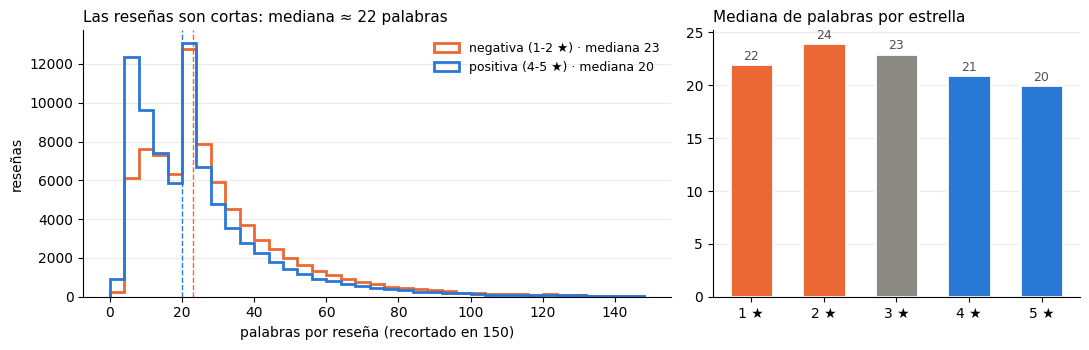

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
bins = np.arange(0, 152, 4)
for nombre, mask, c in [("negativa (1-2 ★)", train["estrellas"] <= 2, C_NEG),
                        ("positiva (4-5 ★)", train["estrellas"] >= 4, C_POS)]:
    p = train.loc[mask, "palabras"].clip(upper=150)
    a1.hist(p, bins=bins, histtype="step", linewidth=2, color=c, label=f"{nombre} · mediana {int(p.median())}")
    a1.axvline(p.median(), color=c, linestyle="--", linewidth=1)
a1.set_xlabel("palabras por reseña (recortado en 150)"); a1.set_ylabel("reseñas")
a1.set_title("Las reseñas son cortas: mediana ≈ 22 palabras", loc="left", fontsize=11)
a1.legend(frameon=False, fontsize=9)

med = train.groupby("estrellas")["palabras"].median()
a2.bar(med.index, med.values, color=[C_NEG, C_NEG, C_NEU, C_POS, C_POS], width=0.6, edgecolor="white", linewidth=2)
for x, v in zip(med.index, med.values):
    a2.text(x, v + 0.4, f"{v:.0f}", ha="center", fontsize=9, color="#52514e")
a2.set_xticks([1, 2, 3, 4, 5], ["1 ★", "2 ★", "3 ★", "4 ★", "5 ★"])
a2.set_title("Mediana de palabras por estrella", loc="left", fontsize=11)
for a in (a1, a2):
    for s in ["top", "right"]: a.spines[s].set_visible(False)
    a.grid(axis="y", alpha=0.25); a.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Lectura:** las reseñas son **cortas**, con una mediana de 22 palabras. Las negativas son **un poco más largas**: mediana de 23 palabras contra 20 de las positivas, y percentil 95 de 75 contra 67. Quien está molesto explica más. Aun así, las dos distribuciones se traslapan casi por completo, así que la longitud sola no separa las clases: hay que mirar **qué palabras** se usan.
El 95 % de las reseñas tiene unas 70 palabras o menos, y eso sirve para fijar la longitud de secuencia del Modelo B (sección 4.2).

## 2. Preparación (sin fuga)

### 2.1 Validación y función de métricas
- **Validación** = partición `validation` del dataset **sin las de 3 estrellas** (4,000 reseñas). Así se parece exactamente a la prueba del cliente, que tampoco tiene 3 estrellas.
- Las métricas son las del cliente, calculadas con **umbral 0.5**. Clase positiva = negativa (1).

In [9]:
v = val[val["estrellas"] != 3]
X_val, y_val = v["text"].values, (v["estrellas"] <= 2).astype(int).values
print("Validación:", len(X_val), "reseñas | negativas:", y_val.sum())

def metricas(y, prob, umbral=0.5):
    yh = (np.asarray(prob).ravel() >= umbral).astype(int)
    r = {"exhaustividad": recall_score(y, yh, zero_division=0),
         "precision": precision_score(y, yh, zero_division=0),
         "exactitud": accuracy_score(y, yh)}
    r["cumple"] = bool(r["exhaustividad"] >= 0.90 and r["precision"] >= 0.85)
    return r

def n_entrenables(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights))

Validación: 4000 reseñas | negativas: 2000


### 2.2 Transformación de los datos (se ajusta solo con train)
**TF‑IDF de unigramas y bigramas**, para el Modelo A y para el experimento de las 3 estrellas:
- `fit_transform` **solo** con los textos de entrenamiento; validación y prueba usan `transform`.
- `max_features=20000` toma los 20,000 n‑gramas más frecuentes **en train**.
- `min_df=2` descarta los n‑gramas que aparecen una sola vez.
- `sublinear_tf` usa log(1+tf), para que una palabra repetida no domine.

La red densa es `Dense(64, relu)` → `Dropout(0.5)` → `Dense(1, sigmoid)`. El dropout es fuerte porque la entrada tiene 20,000 dimensiones y la red se sobreajusta rápido.

In [10]:
def ajustar_tfidf(textos_train):
    vec = TfidfVectorizer(ngram_range=(1, 2), max_features=20000, min_df=2,
                          sublinear_tf=True, dtype=np.float32)
    return vec, vec.fit_transform(textos_train)          # <- ajuste SOLO con train

def red_densa(n_entrada):
    keras.utils.set_random_seed(SEMILLA)
    m = keras.Sequential([keras.Input((n_entrada,)),
                          keras.layers.Dense(64, activation="relu"),
                          keras.layers.Dropout(0.5),
                          keras.layers.Dense(1, activation="sigmoid")], name="tfidf_densa")
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

### 2.3 Decisión sobre las reseñas de 3 estrellas (con validación)
Probamos las tres opciones del PDF con el **mismo** modelo (TF‑IDF + red densa, 3 épocas fijas) y las comparamos en validación. La validación nunca tiene 3 estrellas, igual que la prueba:
- **quitar:** se entrena con 1, 2, 4 y 5 ★ (160,000 reseñas);
- **positivas:** 3 ★ = 0 (200,000 reseñas, 40 % negativas);
- **negativas:** 3 ★ = 1 (200,000 reseñas, 60 % negativas).

In [11]:
def etiquetar(df, opcion):
    if opcion == "quitar":
        d = df[df["estrellas"] != 3]
        return d["text"].values, (d["estrellas"] <= 2).astype(int).values
    if opcion == "positivas":
        return df["text"].values, (df["estrellas"] <= 2).astype(int).values
    if opcion == "negativas":
        return df["text"].values, (df["estrellas"] <= 3).astype(int).values

import gc
exp3 = []
for opcion in ["quitar", "positivas", "negativas"]:
    t0 = time.time()
    Xt_txt, yt = etiquetar(train, opcion)
    vec_o, Xt = ajustar_tfidf(Xt_txt)
    m = red_densa(Xt.shape[1])
    m.fit(Xt, yt, epochs=3, batch_size=512, verbose=0)
    exp3.append({"opcion_3_estrellas": opcion, "n_train": len(yt), "% negativas train": round(yt.mean() * 100, 1),
                 **metricas(y_val, m.predict(vec_o.transform(X_val), verbose=0))})
    print(f"{opcion}: {time.time() - t0:.0f} s", flush=True)
    del m, Xt, vec_o; gc.collect()     # liberar memoria antes de la siguiente opción
exp3 = pd.DataFrame(exp3).round(4)
exp3

quitar: 70 s


positivas: 88 s


negativas: 83 s


,opcion_3_estrellas,n_train,% negativas train,exhaustividad,precision,exactitud,cumple
0,quitar,160000,50.0,0.9285,0.9015,0.9135,True
1,positivas,200000,40.0,0.7970,0.9438,0.8748,False
2,negativas,200000,60.0,0.9710,0.8382,0.8918,False


**Decisión: QUITAR las reseñas de 3 estrellas del entrenamiento.**
*En una línea:* la prueba no trae 3 estrellas y, en validación, quitarlas es la única opción que cumple a la vez exhaustividad ≥ 90 % y precisión ≥ 85 %. Las otras dos opciones desplazan la frontera de decisión: como positivas baja la exhaustividad, y como negativas baja la precisión.

Por qué pasa esto: una reseña de 3 ★ mezcla quejas con elogios. Si le ponemos cualquier etiqueta, el modelo aprende que ese tono mixto pertenece a una clase, y eso mueve dónde cae el umbral de 0.5. Quitarlas además deja las clases 50/50, igual que en la prueba.

### 2.4 Conjunto de entrenamiento definitivo

In [12]:
X_train, y_train = etiquetar(train, "quitar")
print("Entrenamiento:", len(X_train), "| negativas:", y_train.sum(), f"({y_train.mean():.0%})")
print("Validación:   ", len(X_val),   "| negativas:", y_val.sum())

Entrenamiento: 160000 | negativas: 80000 (50%)
Validación:    4000 | negativas: 2000


### 2.5 Cociente de Google (práctica 4)
`cociente = número de muestras de entrenamiento / mediana de palabras por muestra`.
Regla de la práctica: si el cociente es **< 1,500**, conviene un modelo de **bolsa de n‑gramas** (TF‑IDF + densa); si es **≥ 1,500**, conviene uno de **secuencia** (Embedding + RNN/CNN).

In [13]:
mediana_train = float(pd.Series(X_train).str.split().str.len().median())
cociente = len(X_train) / mediana_train
print(f"{len(X_train):,} muestras / {mediana_train:.0f} palabras = cociente {cociente:,.0f}")
print("Sugerencia de la regla:", "secuencia (Embedding + RNN/CNN)" if cociente >= 1500 else "bolsa de n-gramas")

160,000 muestras / 22 palabras = cociente 7,273
Sugerencia de la regla: secuencia (Embedding + RNN/CNN)


**Lectura:** el cociente queda cerca de **7,300**, casi 5 veces el umbral de 1,500. Según la regla, con tantos datos un modelo de secuencia debería poder aprovecharlos, así que entrenamos los dos tipos. La regla es una heurística: la decisión final se toma con los números de validación (sección 5), no con el cociente.

## 3. Línea base trivial
Como las clases están 50/50, no hay clase mayoritaria. La regla trivial que usamos es **marcar todas las reseñas como negativas**: alcanza 100 % de exhaustividad, pero su precisión es de 50 %. Sirve para mostrar por qué el cliente pide **las dos** métricas: marcar todo no le sirve a atención a clientes.

In [14]:
def linea_base(textos):
    return np.ones(len(textos))           # siempre "negativa"

val_res = {"línea base (siempre negativa)": metricas(y_val, linea_base(X_val))}
pd.DataFrame(val_res).T

,exhaustividad,precision,exactitud,cumple
línea base (siempre negativa),1.0,0.5,0.5,False


## 4. Modelos
### 4.1 Modelo A — TF‑IDF (uni + bigramas) + red densa · tipo `conjunto`
Es la misma arquitectura de 2.2, ahora entrenada con el train definitivo. Las épocas las decide **EarlyStopping sobre la pérdida de validación**: paciencia 2, y se recuperan los mejores pesos.

In [15]:
vec_A, Xtr_A = ajustar_tfidf(X_train)        # ajuste SOLO con train
Xva_A = vec_A.transform(X_val)               # validación: solo transform
modelo_A = red_densa(Xtr_A.shape[1])
modelo_A.summary()

t0 = time.time()
hist_A = modelo_A.fit(Xtr_A, y_train, validation_data=(Xva_A, y_val), epochs=10, batch_size=512, verbose=2,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
print(f"Entrenamiento: {time.time() - t0:.0f} s")
val_res["A: TF-IDF bigramas + densa"] = metricas(y_val, modelo_A.predict(Xva_A, verbose=0))
val_res["A: TF-IDF bigramas + densa"]

Model: "tfidf_densa"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │     1,280,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,280,129 (4.88 MB)

 Trainable params: 1,280,129 (4.88 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (7 outputs left out)

Epoch 5/10


313/313 - 18s - 56ms/step - accuracy: 0.9357 - loss: 0.1703 - val_accuracy: 0.9122 - val_loss: 0.2211


Entrenamiento: 88 s


{'exhaustividad': 0.9265,
 'precision': 0.9025815879201169,
 'exactitud': 0.91325,
 'cumple': True}

### 4.2 Tokenización para los modelos de secuencia (sin fuga)
Los modelos de secuencia necesitan la reseña como una **lista de índices de palabras**:
- **Vocabulario:** las 19,998 palabras más frecuentes **de train**, obtenidas con `CountVectorizer` y ajustadas solo con train. El índice 0 queda para el relleno (*padding*) y el 1 para las palabras fuera del vocabulario. Validación y prueba solo se traducen con ese vocabulario.
- **Longitud fija `MAXLEN`:** el percentil 95 de palabras en train. Las reseñas más largas se recortan y las más cortas se rellenan con ceros.

Nota técnica: usamos `CountVectorizer` y no `TextVectorization` de Keras porque esa capa necesita TensorFlow, y aquí usamos el backend de PyTorch.

In [16]:
VOCAB = 20000
tok = CountVectorizer(max_features=VOCAB - 2, lowercase=True).fit(X_train)   # SOLO train
analizador = tok.build_analyzer()
indice = {w: i + 2 for i, w in enumerate(tok.get_feature_names_out())}     # 0 = relleno, 1 = desconocida

MAXLEN = int(np.ceil(np.percentile([len(analizador(t)) for t in X_train], 95)))
print("MAXLEN (percentil 95 de tokens en train):", MAXLEN)

def a_secuencias(textos, maxlen=MAXLEN):
    out = np.zeros((len(textos), maxlen), dtype="int32")
    for r, t in enumerate(textos):
        ids = [indice.get(w, 1) for w in analizador(t)][:maxlen]
        out[r, :len(ids)] = ids
    return out

Xtr_S, Xva_S = a_secuencias(X_train), a_secuencias(X_val)
print("Forma train:", Xtr_S.shape, "| % de tokens de validación fuera del vocabulario:",
      round(100 * (Xva_S == 1).sum() / (Xva_S > 0).sum(), 2))
print("Ejemplo:", X_train[0][:80], "->", Xtr_S[0][:12])

MAXLEN (percentil 95 de tokens en train): 67


Forma train: (160000, 67) | % de tokens de validación fuera del vocabulario: 1.49
Ejemplo: Nada bueno se me fue ka pantalla en menos de 8 meses y no he recibido respuesta  -> [12795  2839 17134 11979  9019 10908 13546  7162 12093  5383 12147 12953]


### 4.3 Modelo B1 — Embedding + Bi‑LSTM · tipo `recurrente`
- **Embedding(20000, 64):** aprende un vector de 64 números para cada palabra, desde cero y con nuestros datos.
- **Bi‑LSTM(64):** lee la reseña de izquierda a derecha y de derecha a izquierda. Así capta el orden y la negación (*«no es malo»* frente a *«es malo»*), cosa que una bolsa de palabras solo capta en parte con los bigramas.
- **Dropout(0.5)** contra el sobreajuste. **EarlyStopping** con paciencia 1, porque estas redes se sobreajustan en 2 o 3 épocas.

In [17]:
def red_secuencia(tipo):
    keras.utils.set_random_seed(SEMILLA)
    ent = keras.Input((MAXLEN,), dtype="int32")
    x = keras.layers.Embedding(VOCAB, 64)(ent)
    if tipo == "bilstm":
        x = keras.layers.Bidirectional(keras.layers.LSTM(64))(x)
    else:  # conv1d
        x = keras.layers.Conv1D(128, 5, activation="relu")(x)
        x = keras.layers.GlobalMaxPooling1D()(x)
    x = keras.layers.Dropout(0.5)(x)
    sal = keras.layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(ent, sal, name=tipo)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

def entrenar_secuencia(tipo):
    m = red_secuencia(tipo); t0 = time.time()
    h = m.fit(Xtr_S, y_train, validation_data=(Xva_S, y_val), epochs=6, batch_size=256, verbose=2,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)])
    print(f"Entrenamiento: {time.time() - t0:.0f} s")
    return m, h

modelo_B1, hist_B1 = entrenar_secuencia("bilstm")
modelo_B1.summary()
val_res["B1: Embedding + Bi-LSTM"] = metricas(y_val, modelo_B1.predict(Xva_S, verbose=0))
val_res["B1: Embedding + Bi-LSTM"]

Epoch 1/6


C:\Users\Paula\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


625/625 - 10s - 17ms/step - accuracy: 0.8688 - loss: 0.3141 - val_accuracy: 0.9000 - val_loss: 0.2538


Epoch 2/6


625/625 - 9s - 15ms/step - accuracy: 0.9183 - loss: 0.2150 - val_accuracy: 0.9103 - val_loss: 0.2272


Epoch 3/6


... (5 outputs left out)

 Trainable params: 1,346,177 (5.14 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,692,356 (10.27 MB)

{'exhaustividad': 0.94,
 'precision': 0.8872109485606419,
 'exactitud': 0.91025,
 'cumple': True}

### 4.4 Modelo B2 — Embedding + Conv1D · tipo `convolucional`
Usa el mismo Embedding, pero en lugar de la LSTM tiene **128 filtros de 5 palabras**: cada filtro detecta una «frase de 5 palabras» típica, como *«no lo recomiendo para nada»*. **GlobalMaxPooling** se queda con la aparición más fuerte de cada filtro, esté donde esté en la reseña. Es más rápida que la LSTM, pero capta menos el orden largo.

In [18]:
modelo_B2, hist_B2 = entrenar_secuencia("conv1d")
modelo_B2.summary()
val_res["B2: Embedding + Conv1D"] = metricas(y_val, modelo_B2.predict(Xva_S, verbose=0))
val_res["B2: Embedding + Conv1D"]

Epoch 1/6


625/625 - 9s - 15ms/step - accuracy: 0.8567 - loss: 0.3318 - val_accuracy: 0.9043 - val_loss: 0.2477


Epoch 2/6


625/625 - 8s - 12ms/step - accuracy: 0.9123 - loss: 0.2260 - val_accuracy: 0.9005 - val_loss: 0.2440


Epoch 3/6


625/625 - 7s - 12ms/step - accuracy: 0.9300 - loss: 0.1860 - val_accuracy: 0.9043 - val_loss: 0.2516


... (4 outputs left out)

 Trainable params: 1,321,217 (5.04 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,642,436 (10.08 MB)

{'exhaustividad': 0.91,
 'precision': 0.8930323846908734,
 'exactitud': 0.9005,
 'cumple': True}

### 4.5 Curvas de aprendizaje (pérdida en validación por época)

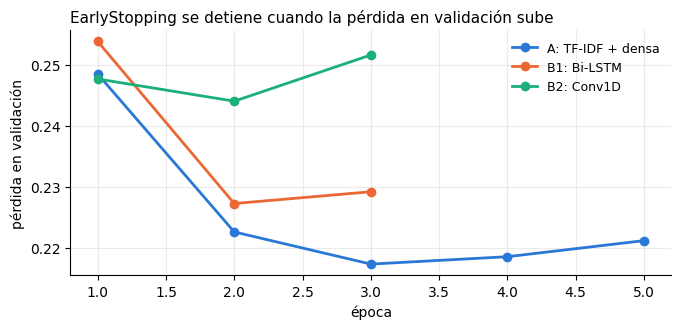

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for nombre, h, c in [("A: TF-IDF + densa", hist_A, "#2a78d6"), ("B1: Bi-LSTM", hist_B1, "#eb6834"),
                     ("B2: Conv1D", hist_B2, "#1baf7a")]:
    vl = h.history["val_loss"]
    ax.plot(range(1, len(vl) + 1), vl, marker="o", markersize=6, linewidth=2, color=c, label=nombre)
ax.set_xlabel("época"); ax.set_ylabel("pérdida en validación")
ax.set_title("EarlyStopping se detiene cuando la pérdida en validación sube", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.grid(alpha=0.25); plt.tight_layout(); plt.show()

### 4.6 Modelo C (opcional)
Según el plan, el modelo con embeddings preentrenados o BETO le corresponde a Andrea. No está incluido en esta versión: el examen pide una línea base y al menos 2 modelos, y aquí hay 3 entrenados por nosotras.

## 5. Elección con validación
**Criterio, fijado antes de ver la prueba:**
1. Solo cuentan los modelos que **cumplen las dos especificaciones en validación**.
2. Entre esos, gana el de **mayor exactitud en validación**.
3. Si hay empate (diferencia < 0.5 puntos), gana el más simple o el que tiene menos parámetros.

In [20]:
modelos = {   # nombre: (modelo, tipo, función que transforma textos crudos en la entrada del modelo)
    "A: TF-IDF bigramas + densa": (modelo_A,  "conjunto",      vec_A.transform),
    "B1: Embedding + Bi-LSTM":    (modelo_B1, "recurrente",    a_secuencias),
    "B2: Embedding + Conv1D":     (modelo_B2, "convolucional", a_secuencias),
}
tabla_val = pd.DataFrame(val_res).T
tabla_val["parametros"] = [0] + [n_entrenables(modelos[k][0]) for k in tabla_val.index[1:]]
display(tabla_val.round(4))

cand = tabla_val.loc[list(modelos)].query("cumple")
if cand.empty:   # si ninguno cumple, elegir el de mayor exactitud y reconocerlo en el folleto
    cand = tabla_val.loc[list(modelos)]
cand = cand.sort_values("exactitud", ascending=False)
mejor = cand.index[0]
empatados = cand[cand["exactitud"] >= cand["exactitud"].iloc[0] - 0.005]
if len(empatados) > 1:
    mejor = empatados.sort_values("parametros").index[0]
ELEGIDO = mejor
print("Modelo elegido con validación:", ELEGIDO)

,exhaustividad,precision,exactitud,cumple,parametros
línea base (siempre negativa),1.0,0.5,0.5,False,0
A: TF-IDF bigramas + densa,0.9265,0.902582,0.91325,True,1280129
B1: Embedding + Bi-LSTM,0.94,0.887211,0.91025,True,1346177
B2: Embedding + Conv1D,0.91,0.893032,0.9005,True,1321217


Modelo elegido con validación: A: TF-IDF bigramas + densa


## 6. Evaluación ÚNICA en la prueba y tabla `resultados`
Esta es la **única** celda que usa `X_prueba` y `y_prueba`. Ya está todo decidido: las 3 estrellas, las épocas y el modelo elegido. Usamos umbral 0.5 y no se ajusta nada después de verla.

In [21]:
filas = []
filas.append({"modelo": "línea base (siempre negativa)", "tipo": "linea base", "parametros": 0,
              **metricas(y_prueba, linea_base(X_prueba))})
prob_prueba = {}
for nombre, (m, tipo, prep) in modelos.items():
    prob_prueba[nombre] = m.predict(prep(X_prueba), verbose=0).ravel()
    filas.append({"modelo": nombre, "tipo": tipo, "parametros": n_entrenables(m),
                  **metricas(y_prueba, prob_prueba[nombre])})

resultados = pd.DataFrame(filas)
resultados["elegido"] = resultados["modelo"] == ELEGIDO
resultados = resultados[["modelo", "tipo", "parametros", "exhaustividad", "precision", "exactitud", "cumple", "elegido"]]
resultados[["exhaustividad", "precision", "exactitud"]] = resultados[["exhaustividad", "precision", "exactitud"]].round(4)
resultados.to_csv("resultados_resenas.csv", index=False)
assert resultados["elegido"].sum() == 1
resultados

C:\Users\Paula\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  outputs, h_n, c_n = torch._VF.lstm(


,modelo,tipo,parametros,exhaustividad,precision,exactitud,cumple,elegido
0,línea base (siempre negativa),linea base,0,1.0000,0.5000,0.5000,False,False
1,A: TF-IDF bigramas + densa,conjunto,1280129,0.9200,0.9113,0.9152,True,True
2,B1: Embedding + Bi-LSTM,recurrente,1346177,0.9350,0.8943,0.9122,True,False
3,B2: Embedding + Conv1D,convolucional,1321217,0.9095,0.8983,0.9032,True,False


In [22]:
yh = (prob_prueba[ELEGIDO] >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_prueba, yh).ravel()
print(f"Modelo elegido: {ELEGIDO}")
print(f"De cada 100 reseñas negativas, marca {100 * tp / (tp + fn):.0f}  (se le escapan {fn} de {tp + fn}).")
print(f"De cada 100 reseñas que marca como negativas, {100 * tp / (tp + fp):.0f} sí lo son  ({fp} falsas alarmas).")
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["real positiva", "real negativa"],
                   columns=["pred. positiva", "pred. negativa"]))

Modelo elegido: A: TF-IDF bigramas + densa
De cada 100 reseñas negativas, marca 92  (se le escapan 160 de 2000).
De cada 100 reseñas que marca como negativas, 91 sí lo son  (179 falsas alarmas).
               pred. positiva  pred. negativa
real positiva            1821             179
real negativa             160            1840


## 7. Justificación de la elección y análisis de 3 errores

### ¿Por qué elegimos el Modelo A (TF‑IDF de uni + bigramas + red densa)?
**1. Lo decidió la validación, con el criterio de la sección 5 fijado antes de ver la prueba.**
Los tres modelos cumplen las especificaciones en validación. A tiene la **mayor exactitud** (91.3 %, contra 91.0 % del Bi‑LSTM y 90.1 % del Conv1D) y también la **mayor precisión** (90.3 %). La diferencia con el Bi‑LSTM es de solo 0.3 puntos, así que en la práctica es un empate (regla 3), y en ese caso también gana A: es el más **simple** y el que tiene **menos parámetros** (1.28 M contra 1.35 M).

**2. Ventajas prácticas para el cliente.** Se entrena en ~1.5 min, predice al instante en una computadora sin GPU y es más fácil de explicar, porque cada n‑grama tiene un peso que se puede revisar (por ejemplo, *«no funciona»* empuja hacia «negativa»).

**3. La prueba confirma, no decide.** En la prueba, con umbral 0.5, A **cumple**: exhaustividad **92.0 %** (meta ≥ 90 %) y precisión **91.1 %** (meta ≥ 85 %).
- En palabras del cliente: *de cada 100 reseñas negativas marca 92* (se le escapan 160 de 2,000), y *de cada 100 que marca como negativas, 91 sí lo son* (179 falsas alarmas entre 2,000 positivas).
- En total se equivoca en 339 de 4,000 reseñas (8.5 %).

**4. ¿Y el cociente de Google?** La regla (cociente 7,273 ≫ 1,500) sugería un modelo de secuencia, pero en validación la bolsa de bigramas empató o ganó. Nuestra explicación:
- las reseñas son cortas (mediana de 22 palabras);
- el sentimiento lo cargan frases cortas que los bigramas sí captan (*«no funciona»*, *«no lo recomiendo»*);
- nuestro Bi‑LSTM aprende los embeddings **desde cero**.

La regla es una guía; la decisión se toma con los datos de validación. La mejora natural sería un modelo de secuencia **preentrenado** (BETO o embeddings multilingües), que sí podría superar a A.

**Alternativa que descartamos:** el Bi‑LSTM tuvo más exhaustividad en la prueba (93.5 %), pero menos precisión (89.4 %). Si el cliente prefiriera «no dejar escapar ninguna queja» aunque haya más falsas alarmas, sería una opción razonable, pero eso se decide con validación y con el cliente, no mirando la prueba.

In [23]:
err = prueba[["estrellas", "text"]].copy()
err["y_real"], err["prob_negativa"] = y_prueba, prob_prueba[ELEGIDO]
err["pred"] = (err["prob_negativa"] >= 0.5).astype(int)
err = err[err["pred"] != err["y_real"]]
print("Errores totales del modelo elegido en la prueba:", len(err), "de", len(prueba))

fn_seguro = err[err["y_real"] == 1].sort_values("prob_negativa").head(1)               # negativa que el modelo ve muy positiva
fp_seguro = err[err["y_real"] == 0].sort_values("prob_negativa", ascending=False).head(1)  # positiva que ve muy negativa
frontera = err.assign(d=(err["prob_negativa"] - 0.5).abs()).sort_values("d").head(1).drop(columns="d")  # la más dudosa
tres = pd.concat([fn_seguro.assign(caso="1) falso negativo seguro"),
                  fp_seguro.assign(caso="2) falso positivo seguro"),
                  frontera.assign(caso="3) error en la frontera")])
for _, r in tres.iterrows():
    print(f"\n{r['caso']} | {r['estrellas']} ★ | real={'negativa' if r['y_real'] else 'positiva'} | P(negativa)={r['prob_negativa']:.3f}\n  «{r['text']}»")

Errores totales del modelo elegido en la prueba: 339 de 4000

1) falso negativo seguro | 2 ★ | real=negativa | P(negativa)=0.013
  «Tallaje un poco grande, compré una L que es mi talla y me sobra de cintura. Por lo demás perfecto, material de muy buena calidad»

2) falso positivo seguro | 4 ★ | real=positiva | P(negativa)=0.996
  «El producto en sí bien porque ya tenía otro y se de qué va el tema, pero muy mal el embalaje. Inexistente. Sin caja de Amazon, tan sólo la caja de propio producto y sin precintar no nada. No es normal, pero ha pasado.»

3) error en la frontera | 5 ★ | real=positiva | P(negativa)=0.502
  «El balón genial. Pero viene con falta de llenado.suerte de tenía un inflador»


### Análisis de los 3 errores (impresos arriba)
**Error 1 · Falso negativo «seguro»: 2 ★ que el modelo ve muy positiva (P = 0.013).**
*«Tallaje un poco grande… Por lo demás perfecto, material de muy buena calidad»*. El texto es casi todo elogio; la queja (la talla) es leve y está dicha en tono neutro. El cliente puso 2 ★, pero el **texto no suena negativo**, así que ningún modelo que lea solo el texto lo marcaría con seguridad.
- **Limitación:** las estrellas y el tono no siempre coinciden; parte del error viene de la etiqueta.
- **Para el negocio:** este cliente sí tiene un problema (la talla), aunque no escribe enojado.

**Error 2 · Falso positivo «seguro»: 4 ★ que el modelo ve muy negativa (P = 0.996).**
*«El producto en sí bien… pero muy mal el embalaje. Inexistente… No es normal»*. Es una reseña **mixta**: la mayor parte del texto es una queja (*«muy mal»*, *«inexistente»*, *«no es normal»*), y la bolsa de palabras no sabe que *«en sí bien»* es lo que pesa en la calificación.
- **Para atención a clientes este «error» es útil:** hay una queja real sobre el embalaje que vale la pena atender.
- **Lo que muestra:** el modelo detecta *quejas*, no exactamente *estrellas*.

**Error 3 · Error en la frontera: 5 ★ con P = 0.502.**
*«El balón genial. Pero viene con falta de llenado.suerte de tenía un inflador»*. Otra vez es un elogio seguido de *«pero»* y un defecto. Además tiene errores de escritura (*«llenado.suerte»* sin espacio se vuelve un token raro que el vocabulario no conoce). Queda **0.002 por encima** del umbral, así que se marca como negativa. **No movemos el umbral**: está fijo en 0.5 por las reglas del cliente y del examen.

**Patrón común:** 2 de los 3 errores son **reseñas mixtas** («bien…, pero…»). Un modelo de bolsa de palabras no sabe qué parte de la reseña pesa más. Esta es la limitación principal para el folleto, y la propuesta de mejora es un modelo que entienda el orden y el contraste, como BETO ajustado.

## 8. Guardar el modelo elegido en `modelo/`
Guardamos dos archivos, porque el modelo necesita el mismo preprocesamiento que en el entrenamiento:
- `modelo/modelo_resenas.keras`: la red;
- `modelo/preprocesador_resenas.joblib`: el TF‑IDF o el vocabulario, ajustados con train.

Después comprobamos que, al recargarlos, las predicciones son las mismas. Este es el paso que usaría el PMV.

In [24]:
os.makedirs("modelo", exist_ok=True)
m_elegido, tipo_elegido, _ = modelos[ELEGIDO]
m_elegido.save("modelo/modelo_resenas.keras")
if tipo_elegido == "conjunto":
    if hasattr(vec_A, "stop_words_"):
        vec_A.stop_words_ = None          # atributo enorme que no se usa para predecir
    prep_guardar = {"tipo": "tfidf", "vectorizador": vec_A}
else:
    prep_guardar = {"tipo": "secuencia", "indice": indice, "maxlen": MAXLEN,
                    "vocab": VOCAB, "analizador": "CountVectorizer(lowercase=True)"}
joblib.dump(prep_guardar, "modelo/preprocesador_resenas.joblib")
for f in os.listdir("modelo"):
    print(f, f"{os.path.getsize(os.path.join('modelo', f)) / 1e6:.1f} MB")

.gitkeep 0.0 MB
modelo_resenas.keras 15.4 MB
preprocesador_resenas.joblib 0.7 MB


In [25]:
# Comprobación: recargar y predecir
m2 = keras.models.load_model("modelo/modelo_resenas.keras")
p2 = joblib.load("modelo/preprocesador_resenas.joblib")
transformar = p2["vectorizador"].transform if p2["tipo"] == "tfidf" else a_secuencias
assert np.allclose(m2.predict(transformar(X_prueba[:50]), verbose=0).ravel(), prob_prueba[ELEGIDO][:50], atol=1e-5)

nuevas = ["Llegó roto y el vendedor no contesta. No lo recomiendo.",
          "Muy buena calidad, llegó antes de lo esperado. Lo volvería a comprar."]
for t, p in zip(nuevas, m2.predict(transformar(nuevas), verbose=0).ravel()):
    print(f"P(negativa)={p:.3f} -> {'NEGATIVA: atender primero' if p >= 0.5 else 'no negativa'} | {t}")

P(negativa)=0.998 -> NEGATIVA: atender primero | Llegó roto y el vendedor no contesta. No lo recomiendo.
P(negativa)=0.004 -> no negativa | Muy buena calidad, llegó antes de lo esperado. Lo volvería a comprar.
